<a href="https://colab.research.google.com/github/uniqueeee777/stability-aware-multiview-food-security/blob/main/03_Baseline_Grid_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Persiapan Data

In [ ]:

# ============================================================
# CELL 1 — GRID SEARCH SETUP
# ============================================================

!pip -q install "kmedoids==0.5.5"

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from importlib.metadata import version

import kmedoids
import numpy as np
import pandas as pd
import scipy
import sklearn
import hashlib
import json

drive.mount("/content/drive")

SEED = 20261018

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

REP_RUN = "20261018_173812_UTC"

REP_DIR = (
    ROOT / "03_outputs"
    / "02_representation" / REP_RUN
)

RAW_FILE = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

EXPECTED_HASH = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

assert RAW_FILE.exists()
assert hashlib.sha256(
    RAW_FILE.read_bytes()
).hexdigest() == EXPECTED_HASH

source = REP_DIR / "R0_raw_zscore_distances.npz"

assert source.exists(), f"File tidak ditemukan: {source}"

# Diubah menjadi allow_pickle=True karena array 'kode_bps' bertipe Object (string)
with np.load(source, allow_pickle=True) as data:
    D_ref = data["fused"].copy()
    Phi = data["euclidean_features"].copy()
    ids = data["kode_bps"].astype(str)

    D_views = {
        "Food": data["food"].copy(),
        "Climate": data["climate"].copy(),
        "Accessibility": data["accessibility"].copy()
    }

df = pd.read_csv(
    RAW_FILE,
    dtype={"kode_bps": "string"}
)

assert df.shape == (85, 13)
assert np.array_equal(
    ids, df["kode_bps"].astype(str).to_numpy()
)

assert D_ref.shape == (85, 85)
assert Phi.shape == (85, 9)
assert np.isfinite(D_ref).all()
assert np.allclose(D_ref, D_ref.T)
assert np.allclose(np.diag(D_ref), 0)

# Verifikasi equivalence: distance vs Euclidean embedding
assert np.allclose(
    squareform(pdist(Phi)),
    D_ref,
    atol=1e-10
)

RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_UTC"
)

OUT3 = (
    ROOT / "03_outputs"
    / "03_gridsearch_pilot" / RUN_ID
)

OUT3.mkdir(parents=True, exist_ok=True)

print("NOTEBOOK 03 SETUP SUCCESSFUL")
print("Wilayah:", len(df))
print("R0 distance matrix:", D_ref.shape)
print("Source run:", REP_RUN)
print("Output:", OUT3)
print("kmedoids:", version("kmedoids"))
print("scikit-learn:", sklearn.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 kB 14.4 MB/s eta 0:00:00
Mounted at /content/drive
NOTEBOOK 03 SETUP SUCCESSFUL
Wilayah: 85
R0 distance matrix: (85, 85)
Source run: 20261018_173812_UTC
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/03_gridsearch_pilot/20261019_012231_UTC
kmedoids: 0.5.5
scikit-learn: 1.6.1


## Rekonstruksi graf yang identik

In [ ]:

# ============================================================
# CELL 2 — RECONSTRUCT VALIDATED AFFINITY GRAPHS
# ============================================================

K_GRAPH_GRID = [5, 8, 12, 16, 24]
K_SCALE = 7

VIEW_WEIGHTS = {
    "Food": 1 / 3,
    "Climate": 1 / 3,
    "Accessibility": 1 / 3
}

def affinity_graph(D, k_graph, k_scale=7):

    D = np.asarray(D, dtype=float)
    n = D.shape[0]

    assert D.shape == (n, n)
    assert np.allclose(D, D.T)
    assert np.allclose(np.diag(D), 0)
    assert np.isfinite(D).all()
    assert (D >= 0).all()
    assert 1 <= k_graph < n
    assert 1 <= k_scale < n

    D_tmp = D.copy()
    np.fill_diagonal(D_tmp, np.inf)

    order = np.argsort(
        D_tmp, axis=1, kind="stable"
    )

    sigma = np.take_along_axis(
        D_tmp,
        order[:, [k_scale - 1]],
        axis=1
    ).ravel()

    if (sigma <= 0).any() or not np.isfinite(sigma).all():
        raise ValueError("Invalid local bandwidth.")

    adjacency = np.zeros((n, n), dtype=bool)

    adjacency[
        np.arange(n)[:, None],
        order[:, :k_graph]
    ] = True

    adjacency = adjacency | adjacency.T

    W = np.exp(
        -(D ** 2)
        / (sigma[:, None] * sigma[None, :])
    )

    W = np.where(adjacency, W, 0.0)
    np.fill_diagonal(W, 0.0)

    assert np.allclose(W, W.T)

    n_comp = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if n_comp != 1:
        raise ValueError(
            f"Graph disconnected: {n_comp} components."
        )

    return W


GRAPH_STORE = {}

for kg in K_GRAPH_GRID:

    # Early fusion: single graph on R0 distance
    W_early = affinity_graph(
        D_ref, kg, K_SCALE
    )

    # Multi-view: three graphs, then fusion
    individual = {
        v: affinity_graph(D, kg, K_SCALE)
        for v, D in D_views.items()
    }

    W_fused = sum(
        VIEW_WEIGHTS[v] * W / np.linalg.norm(W, "fro")
        for v, W in individual.items()
    )

    assert np.allclose(W_fused, W_fused.T)
    assert np.allclose(np.diag(W_fused), 0)

    assert connected_components(
        (W_fused > 0).astype(np.uint8),
        directed=False
    )[0] == 1

    GRAPH_STORE[("early", kg)] = W_early
    GRAPH_STORE[("multiview", kg)] = W_fused


# Cross-check with Notebook 02 saved diagnostics
qc_path = REP_DIR / "graph_diagnostics.csv"
assert qc_path.exists()

old_qc = pd.read_csv(qc_path)

for kg in K_GRAPH_GRID:

    row = old_qc.loc[
        (old_qc["representation"] == "R0_raw_zscore")
        & (old_qc["graph"] == "FUSED")
        & (old_qc["k_graph"] == kg)
    ]

    assert len(row) == 1

    W = GRAPH_STORE[("multiview", kg)]

    density = (
        np.count_nonzero(np.triu(W, k=1))
        / (85 * 84 / 2)
    )

    assert np.isclose(
        density,
        row["edge_density"].iloc[0],
        atol=1e-10
    )

print("ALL GRAPH RECONSTRUCTIONS VERIFIED")
print("Graph configurations:", len(GRAPH_STORE))


ALL GRAPH RECONSTRUCTIONS VERIFIED
Graph configurations: 10


## Grid Search baseline dan multi-view, tanpa pemilihan final

In [ ]:

# ============================================================
# CELL 3 — STAGE 1 GRID SEARCH
# Quality assessment only; no final model selection
# ============================================================

K_GRID = range(2, 7)

records = []

labels_wide = df[
    ["kode_bps", "provinsi", "kabupaten_kota"]
].copy()


def register_candidate(
    method,
    k,
    labels,
    k_graph=None,
    objective_loss=np.nan
):
    labels = np.asarray(labels, dtype=int)

    if labels.shape != (85,):
        raise ValueError("Invalid label dimensions.")

    unique, counts = np.unique(
        labels, return_counts=True
    )

    if len(unique) != k:
        raise ValueError(
            f"{method}: expected {k}, "
            f"found {len(unique)} clusters."
        )

    s = silhouette_samples(
        D_ref,
        labels,
        metric="precomputed"
    )

    score = silhouette_score(
        D_ref,
        labels,
        metric="precomputed"
    )

    model_id = (
        f"{method}_K{k}"
        + (f"_KG{k_graph}" if k_graph is not None else "")
    )

    records.append({
        "model_id": model_id,
        "method": method,
        "K": k,
        "k_graph": k_graph,
        "k_scale": K_SCALE if k_graph is not None else np.nan,
        "silhouette": float(score),
        "negative_silhouette_pct": float(
            100 * np.mean(s < 0)
        ),
        "smallest_cluster": int(counts.min()),
        "largest_cluster": int(counts.max()),
        "clusters_size_le_2": int(
            np.sum(counts <= 2)
        ),
        "pam_objective_loss": objective_loss,
        "cluster_sizes": json.dumps(
            counts.tolist()
        )
    })

    labels_wide[model_id] = labels


# ------------------------------------------------------------
# A. K-MEDOIDS: ORIGINAL PAM
# ------------------------------------------------------------

for k in K_GRID:

    fitted = kmedoids.pam(
        D_ref,
        k,
        init="build",
        max_iter=300,
        random_state=SEED
    )

    register_candidate(
        method="KMedoids_PAM",
        k=k,
        labels=fitted.labels,
        objective_loss=float(fitted.loss)
    )


# ------------------------------------------------------------
# B. HIERARCHICAL
# ------------------------------------------------------------

Z_ward = linkage(
    Phi,
    method="ward",
    metric="euclidean"
)

condensed = squareform(
    D_ref, checks=True
)

Z_average = linkage(
    condensed,
    method="average"
)

Z_complete = linkage(
    condensed,
    method="complete"
)

LINKAGES = {
    "Ward": Z_ward,
    "Average": Z_average,
    "Complete": Z_complete
}

for name, Z_tree in LINKAGES.items():

    for k in K_GRID:

        labels = cut_tree(
            Z_tree,
            n_clusters=k
        ).ravel()

        register_candidate(
            method=f"Hierarchical_{name}",
            k=k,
            labels=labels
        )


# ------------------------------------------------------------
# C. SPECTRAL: EARLY FUSION vs MULTI-VIEW FUSION
# ------------------------------------------------------------

for graph_type in ["early", "multiview"]:

    method_name = (
        "Spectral_Early"
        if graph_type == "early"
        else "Spectral_MultiView"
    )

    for kg in K_GRAPH_GRID:

        W = GRAPH_STORE[(graph_type, kg)]

        for k in K_GRID:

            model = SpectralClustering(
                n_clusters=k,
                affinity="precomputed",
                assign_labels="kmeans",
                random_state=SEED,
                n_init=20
            )

            labels = model.fit_predict(W)

            register_candidate(
                method=method_name,
                k=k,
                labels=labels,
                k_graph=kg
            )


# ------------------------------------------------------------
# D. SAVE ALL RESULTS
# ------------------------------------------------------------

grid_results = pd.DataFrame(records)

assert len(grid_results) == 70
assert labels_wide.shape[1] == 73

grid_results = grid_results.sort_values(
    "silhouette",
    ascending=False
).reset_index(drop=True)

grid_results.to_csv(
    OUT3 / "gridsearch_R0_all_candidates.csv",
    index=False
)

labels_wide.to_csv(
    OUT3 / "gridsearch_R0_all_labels.csv",
    index=False
)

manifest = {
    "run_id": RUN_ID,
    "source_run": REP_RUN,
    "input_sha256": EXPECTED_HASH,
    "representation": "R0_raw_zscore",
    "reference_distance": "R0_fused_euclidean",
    "K_grid": list(K_GRID),
    "k_graph_grid": K_GRAPH_GRID,
    "k_scale": K_SCALE,
    "view_weights": VIEW_WEIGHTS,
    "pam_initialization": "build",
    "spectral_n_init": 20,
    "random_seed": SEED,
    "kmedoids_version": version("kmedoids"),
    "sklearn_version": sklearn.__version__,
    "scipy_version": scipy.__version__,
    "numpy_version": np.__version__,
    "status": "EXPLORATORY_ONLY_NOT_FINAL_SELECTION"
}

(OUT3 / "gridsearch_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("GRID SEARCH STAGE 1 COMPLETED")
print("Configurations:", len(grid_results))

print("\nTop 15 configurations by Silhouette:")
display(
    grid_results[
        [
            "method", "K", "k_graph",
            "silhouette",
            "negative_silhouette_pct",
            "smallest_cluster",
            "largest_cluster",
            "clusters_size_le_2"
        ]
    ].head(15).round(4)
)

print("\nBest observed score PER METHOD (diagnostic):")
display(
    grid_results.loc[
        grid_results.groupby("method")[
            "silhouette"
        ].idxmax(),
        [
            "method", "K", "k_graph",
            "silhouette", "smallest_cluster"
        ]
    ].sort_values(
        "silhouette",
        ascending=False
    ).round(4)
)

print("\nSaved:", OUT3)


GRID SEARCH STAGE 1 COMPLETED
Configurations: 70

Top 15 configurations by Silhouette:


,method,K,k_graph,silhouette,negative_silhouette_pct,smallest_cluster,largest_cluster,clusters_size_le_2
0,Hierarchical_Average,2,NaN,0.3203,0.0000,4,81,0
1,Hierarchical_Complete,2,NaN,0.3090,9.4118,14,71,0
2,Spectral_MultiView,2,24.0,0.3079,1.1765,21,64,0
3,Spectral_Early,3,16.0,0.2904,3.5294,17,39,0
4,Spectral_Early,3,12.0,0.2886,5.8824,15,41,0
5,Spectral_Early,3,24.0,0.2881,5.8824,17,41,0
6,Spectral_Early,3,8.0,0.2870,7.0588,15,42,0
7,KMedoids_PAM,3,NaN,0.2835,5.8824,15,39,0
8,Spectral_Early,3,5.0,0.2829,5.8824,14,41,0
9,Hierarchical_Ward,2,NaN,0.2805,8.2353,18,67,0



Best observed score PER METHOD (diagnostic):


,method,K,k_graph,silhouette,smallest_cluster
0,Hierarchical_Average,2,NaN,0.3203,4
1,Hierarchical_Complete,2,NaN,0.3090,14
2,Spectral_MultiView,2,24.0,0.3079,21
3,Spectral_Early,3,16.0,0.2904,17
7,KMedoids_PAM,3,NaN,0.2835,15
9,Hierarchical_Ward,2,NaN,0.2805,18



Saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/03_gridsearch_pilot/20261019_012231_UTC


## Profil cluster, keanggotaan wilayah, dan kualitas setiap view

In [ ]:

# ============================================================
# CELL 4 — CANDIDATE PROFILING
# No new model fitting
# References:
# Rousseeuw (1987): silhouette
# ============================================================

from sklearn.metrics import silhouette_score, silhouette_samples
from IPython.display import display

import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# 1. LOAD RESULTS FROM THE SAME PILOT RUN
# ------------------------------------------------------------

results = pd.read_csv(
    OUT3 / "gridsearch_R0_all_candidates.csv"
)

saved_labels = pd.read_csv(
    OUT3 / "gridsearch_R0_all_labels.csv",
    dtype={"kode_bps": "string"}
)

assert len(results) == 70
assert len(saved_labels) == 85

assert np.array_equal(
    saved_labels["kode_bps"].astype(str).to_numpy(),
    df["kode_bps"].astype(str).to_numpy()
)

FEATURES = (
    [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan",
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem",
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
)

# ------------------------------------------------------------
# 2. SELECT CANDIDATES FOR DIAGNOSTICS ONLY
# ------------------------------------------------------------

best_indices = results.groupby(
    "method"
)["silhouette"].idxmax().tolist()

# Inspect K=3 for methods where it is substantively useful
for method in [
    "Hierarchical_Average",
    "Spectral_MultiView"
]:
    subset = results.loc[
        (results["method"] == method)
        & (results["K"] == 3)
    ]

    if not subset.empty:
        best_indices.append(
            subset["silhouette"].idxmax()
        )

candidates = (
    results.loc[sorted(set(best_indices))]
    .sort_values("silhouette", ascending=False)
    .reset_index(drop=True)
)

assert candidates["model_id"].is_unique

print("CANDIDATES FOR DIAGNOSTICS:")
display(
    candidates[
        [
            "model_id", "K", "silhouette",
            "smallest_cluster", "largest_cluster"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 3. PROFILES ON ORIGINAL INDICATOR SCALE
# ------------------------------------------------------------

X_raw = df[FEATURES].astype(float)

# Standardized means for comparability in profiling.
# This is only descriptive, not another clustering step.
Z_profile = (
    (X_raw - X_raw.mean())
    / X_raw.std(ddof=1)
)

profile_rows = []
membership_rows = []
view_rows = []

for row in candidates.itertuples(index=False):

    model_id = row.model_id
    labels = saved_labels[model_id].to_numpy(
        dtype=int
    )

    assert len(labels) == len(df)
    assert len(np.unique(labels)) == row.K

    # Common-reference silhouette per observation
    sil_samples = silhouette_samples(
        D_ref, labels,
        metric="precomputed"
    )

    # Separate diagnostic quality by view
    view_record = {
        "model_id": model_id,
        "method": row.method,
        "K": row.K,
        "silhouette_reference": row.silhouette
    }

    for view, D in D_views.items():
        view_record[f"sil_{view.lower()}"] = (
            silhouette_score(
                D, labels,
                metric="precomputed"
            )
        )

    view_rows.append(view_record)

    for cluster_id in sorted(np.unique(labels)):

        mask = labels == cluster_id
        n_cluster = int(mask.sum())

        profile = {
            "model_id": model_id,
            "method": row.method,
            "K": row.K,
            "cluster": int(cluster_id),
            "n": n_cluster,
            "mean_silhouette": float(
                sil_samples[mask].mean()
            ),
            "n_negative_silhouette": int(
                (sil_samples[mask] < 0).sum()
            )
        }

        # Mean standardized profile for all 9 indicators
        for col in FEATURES:
            profile[f"zmean_{col}"] = float(
                Z_profile.loc[mask, col].mean()
            )

        profile_rows.append(profile)

        indices = np.flatnonzero(mask)

        for idx in indices:

            membership_rows.append({
                "model_id": model_id,
                "cluster": int(cluster_id),
                "cluster_size": n_cluster,
                "kode_bps": str(
                    df.iloc[idx]["kode_bps"]
                ),
                "provinsi": df.iloc[idx]["provinsi"],
                "kabupaten_kota": (
                    df.iloc[idx]["kabupaten_kota"]
                ),
                "silhouette_reference": float(
                    sil_samples[idx]
                )
            })

profiles = pd.DataFrame(profile_rows)
memberships = pd.DataFrame(membership_rows)
view_scores = pd.DataFrame(view_rows)

# ------------------------------------------------------------
# 4. IDENTIFY SMALL CLUSTERS FOR MANUAL REVIEW
# ------------------------------------------------------------

print("\nCLUSTERS WITH FIVE OR FEWER REGIONS:")

small_clusters = memberships.loc[
    memberships["cluster_size"] <= 5
].sort_values([
    "model_id", "cluster", "kabupaten_kota"
])

if small_clusters.empty:
    print("No clusters with <= 5 regions.")
else:
    display(
        small_clusters[
            [
                "model_id", "cluster",
                "provinsi", "kabupaten_kota"
            ]
        ]
    )

print("\nSILHOUETTE BY VIEW:")
display(view_scores.round(4))

print("\nSTANDARDIZED CLUSTER PROFILES:")
display(profiles.round(3))

# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

profiles.to_csv(
    OUT3 / "candidate_cluster_profiles.csv",
    index=False
)

memberships.to_csv(
    OUT3 / "candidate_cluster_memberships.csv",
    index=False
)

view_scores.to_csv(
    OUT3 / "candidate_view_silhouettes.csv",
    index=False
)

print("\nCELL 4 COMPLETED")


CANDIDATES FOR DIAGNOSTICS:


,model_id,K,silhouette,smallest_cluster,largest_cluster
0,Hierarchical_Average_K2,2,0.3203,4,81
1,Hierarchical_Complete_K2,2,0.3090,14,71
2,Spectral_MultiView_K2_KG24,2,0.3079,21,64
3,Spectral_Early_K3_KG16,3,0.2904,17,39
4,KMedoids_PAM_K3,3,0.2835,15,39
5,Hierarchical_Ward_K2,2,0.2805,18,67
6,Hierarchical_Average_K3,3,0.2569,1,81
7,Spectral_MultiView_K3_KG24,3,0.1757,16,43



CLUSTERS WITH FIVE OR FEWER REGIONS:


,model_id,cluster,provinsi,kabupaten_kota
81,Hierarchical_Average_K2,1,Maluku,Kota Ambon
84,Hierarchical_Average_K2,1,Papua,Kota Jayapura
82,Hierarchical_Average_K2,1,Nusa Tenggara Timur,Kota Kupang
83,Hierarchical_Average_K2,1,Papua Barat Daya,Kota Sorong
591,Hierarchical_Average_K3,1,Maluku,Kota Ambon
594,Hierarchical_Average_K3,2,Papua,Kota Jayapura
592,Hierarchical_Average_K3,2,Nusa Tenggara Timur,Kota Kupang
593,Hierarchical_Average_K3,2,Papua Barat Daya,Kota Sorong



SILHOUETTE BY VIEW:


,model_id,method,K,silhouette_reference,sil_food,sil_climate,sil_accessibility
0,Hierarchical_Average_K2,Hierarchical_Average,2,0.3203,0.1497,0.2732,0.4792
1,Hierarchical_Complete_K2,Hierarchical_Complete,2,0.3090,0.4130,-0.0364,0.4303
2,Spectral_MultiView_K2_KG24,Spectral_MultiView,2,0.3079,0.4556,-0.0020,0.3852
3,Spectral_Early_K3_KG16,Spectral_Early,3,0.2904,0.1536,0.2332,0.0471
4,KMedoids_PAM_K3,KMedoids_PAM,3,0.2835,0.1477,0.2338,0.0589
5,Hierarchical_Ward_K2,Hierarchical_Ward,2,0.2805,0.4799,0.0095,0.2678
6,Hierarchical_Average_K3,Hierarchical_Average,3,0.2569,0.0813,0.0996,0.2987
7,Spectral_MultiView_K3_KG24,Spectral_MultiView,3,0.1757,0.2685,0.0355,0.1451



STANDARDIZED CLUSTER PROFILES:


,model_id,method,K,cluster,n,mean_silhouette,n_negative_silhouette,zmean_F1_ikp_ketersediaan,zmean_F2_ikp_keterjangkauan,zmean_F3_ikp_pemanfaatan,zmean_C1_anomali_hujan_mm,zmean_C2_cdd_hari,zmean_C3_hari_hujan_ekstrem,zmean_A1_persen_tanpa_angkutan,zmean_A2_persen_jalan_tanah_lainnya,zmean_A3_persen_tanpa_pertokoan_pasar
0,Hierarchical_Average_K2,Hierarchical_Average,2,0,81,0.325,0,0.026,-0.063,-0.076,-0.028,-0.009,-0.025,0.039,0.039,0.159
1,Hierarchical_Average_K2,Hierarchical_Average,2,1,4,0.233,0,-0.520,1.283,1.543,0.569,0.186,0.506,-0.796,-0.795,-3.223
2,Hierarchical_Complete_K2,Hierarchical_Complete,2,0,71,0.302,7,0.192,0.305,0.305,0.090,0.098,0.046,-0.280,-0.340,-0.086
3,Hierarchical_Complete_K2,Hierarchical_Complete,2,1,14,0.343,1,-0.974,-1.546,-1.547,-0.458,-0.496,-0.236,1.418,1.726,0.434
4,Spectral_MultiView_K2_KG24,Spectral_MultiView,2,0,64,0.302,1,0.322,0.444,0.425,0.155,0.137,0.054,-0.359,-0.446,-0.166
5,Spectral_MultiView_K2_KG24,Spectral_MultiView,2,1,21,0.328,0,-0.983,-1.352,-1.295,-0.472,-0.416,-0.164,1.095,1.360,0.506
6,Spectral_Early_K3_KG16,Spectral_Early,3,0,29,0.351,0,0.677,0.521,0.322,-0.655,0.917,-0.954,-0.622,-0.661,-0.374
7,Spectral_Early_K3_KG16,Spectral_Early,3,1,39,0.212,3,-0.031,0.286,0.425,0.807,-0.525,0.852,-0.009,-0.133,0.014
8,Spectral_Early_K3_KG16,Spectral_Early,3,2,17,0.368,0,-1.084,-1.546,-1.523,-0.733,-0.360,-0.328,1.081,1.433,0.607
9,KMedoids_PAM_K3,KMedoids_PAM,3,0,39,0.195,4,0.009,0.220,0.361,0.803,-0.572,0.877,0.119,-0.036,0.036



CELL 4 COMPLETED


## Kesepakatan antarmodel dan distribusi ukuran cluster
Cell ini menghitung ARI untuk konfigurasi yang kita inspeksi dan menampilkan kualitas terbaik pada setiap kombinasi metode dan jumlah cluster. Hasilnya membantu memisahkan kemungkinan struktur dua cluster dan tiga cluster sebelum pengujian stabilitas.

In [ ]:

# ============================================================
# CELL 5 — CROSS-MODEL AGREEMENT & K DIAGNOSTICS
# References:
# Hubert & Arabie (1985): Adjusted Rand Index
# ============================================================

from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# ------------------------------------------------------------
# 1. ARI BETWEEN FULL-DATA CANDIDATE PARTITIONS
# ------------------------------------------------------------

model_ids = candidates["model_id"].tolist()

ari_matrix = pd.DataFrame(
    np.eye(len(model_ids)),
    index=model_ids,
    columns=model_ids
)

agreement_rows = []

for a, b in combinations(model_ids, 2):

    labels_a = saved_labels[a].to_numpy(dtype=int)
    labels_b = saved_labels[b].to_numpy(dtype=int)

    ari = adjusted_rand_score(
        labels_a, labels_b
    )

    ari_matrix.loc[a, b] = ari
    ari_matrix.loc[b, a] = ari

    agreement_rows.append({
        "model_a": a,
        "model_b": b,
        "ARI": float(ari)
    })

agreement = (
    pd.DataFrame(agreement_rows)
    .sort_values("ARI", ascending=False)
)

print("CROSS-MODEL ADJUSTED RAND INDEX:")
display(ari_matrix.round(3))

print("\nTOP MODEL AGREEMENTS:")
display(agreement.head(15).round(3))

# ------------------------------------------------------------
# 2. BEST GRID CONFIGURATION PER METHOD AND K
#    Diagnostic, not final selection
# ------------------------------------------------------------

indices = (
    results.groupby(["method", "K"])["silhouette"]
    .idxmax()
)

quality_by_k = (
    results.loc[
        indices,
        [
            "method", "K", "k_graph",
            "silhouette", "smallest_cluster",
            "largest_cluster", "clusters_size_le_2"
        ]
    ]
    .sort_values(["method", "K"])
    .reset_index(drop=True)
)

print("\nQUALITY BY METHOD AND K:")
display(quality_by_k.round(4))

# ------------------------------------------------------------
# 3. PROVINCE COMPOSITION FOR INSPECTED CANDIDATES
# ------------------------------------------------------------

province_composition = (
    memberships.groupby(
        ["model_id", "cluster", "provinsi"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "n_wilayah"})
)

print("\nPROVINCE COMPOSITION:")
display(province_composition)

# ------------------------------------------------------------
# 4. SAVE
# ------------------------------------------------------------

ari_matrix.to_csv(
    OUT3 / "candidate_ARI_matrix.csv"
)

agreement.to_csv(
    OUT3 / "candidate_pairwise_ARI.csv",
    index=False
)

quality_by_k.to_csv(
    OUT3 / "quality_by_method_and_K.csv",
    index=False
)

province_composition.to_csv(
    OUT3 / "candidate_province_composition.csv",
    index=False
)

print("\nCELL 5 COMPLETED")
print("Saved:", OUT3)


CROSS-MODEL ADJUSTED RAND INDEX:


,Hierarchical_Average_K2,Hierarchical_Complete_K2,Spectral_MultiView_K2_KG24,Spectral_Early_K3_KG16,KMedoids_PAM_K3,Hierarchical_Ward_K2,Hierarchical_Average_K3,Spectral_MultiView_K3_KG24
Hierarchical_Average_K2,1.000,-0.060,-0.053,-0.011,-0.012,-0.057,0.995,-0.031
Hierarchical_Complete_K2,-0.060,1.000,0.657,0.183,0.175,0.427,-0.062,0.282
Spectral_MultiView_K2_KG24,-0.053,0.657,1.000,0.359,0.311,0.667,-0.055,0.425
Spectral_Early_K3_KG16,-0.011,0.183,0.359,1.000,0.857,0.353,-0.010,0.475
KMedoids_PAM_K3,-0.012,0.175,0.311,0.857,1.000,0.350,-0.012,0.463
Hierarchical_Ward_K2,-0.057,0.427,0.667,0.353,0.350,1.000,-0.059,0.352
Hierarchical_Average_K3,0.995,-0.062,-0.055,-0.010,-0.012,-0.059,1.000,-0.033
Spectral_MultiView_K3_KG24,-0.031,0.282,0.425,0.475,0.463,0.352,-0.033,1.000



TOP MODEL AGREEMENTS:


,model_a,model_b,ARI
5,Hierarchical_Average_K2,Hierarchical_Average_K3,0.995
18,Spectral_Early_K3_KG16,KMedoids_PAM_K3,0.857
15,Spectral_MultiView_K2_KG24,Hierarchical_Ward_K2,0.667
7,Hierarchical_Complete_K2,Spectral_MultiView_K2_KG24,0.657
21,Spectral_Early_K3_KG16,Spectral_MultiView_K3_KG24,0.475
24,KMedoids_PAM_K3,Spectral_MultiView_K3_KG24,0.463
10,Hierarchical_Complete_K2,Hierarchical_Ward_K2,0.427
17,Spectral_MultiView_K2_KG24,Spectral_MultiView_K3_KG24,0.425
13,Spectral_MultiView_K2_KG24,Spectral_Early_K3_KG16,0.359
19,Spectral_Early_K3_KG16,Hierarchical_Ward_K2,0.353



QUALITY BY METHOD AND K:


,method,K,k_graph,silhouette,smallest_cluster,largest_cluster,clusters_size_le_2
0,Hierarchical_Average,2,NaN,0.3203,4,81,0
1,Hierarchical_Average,3,NaN,0.2569,1,81,1
2,Hierarchical_Average,4,NaN,0.2524,1,64,1
3,Hierarchical_Average,5,NaN,0.2184,1,64,3
4,Hierarchical_Average,6,NaN,0.2631,1,36,3
5,Hierarchical_Complete,2,NaN,0.3090,14,71,0
6,Hierarchical_Complete,3,NaN,0.1924,9,62,0
7,Hierarchical_Complete,4,NaN,0.1836,9,47,0
8,Hierarchical_Complete,5,NaN,0.1903,2,47,1
9,Hierarchical_Complete,6,NaN,0.1647,2,40,1



PROVINCE COMPOSITION:


,model_id,cluster,provinsi,n_wilayah
0,Hierarchical_Average_K2,0,Maluku,10
1,Hierarchical_Average_K2,0,Maluku Utara,10
2,Hierarchical_Average_K2,0,Nusa Tenggara Timur,21
3,Hierarchical_Average_K2,0,Papua,8
4,Hierarchical_Average_K2,0,Papua Barat,7
...,...,...,...,...
114,Spectral_MultiView_K3_KG24,2,Papua Barat,4
115,Spectral_MultiView_K3_KG24,2,Papua Barat Daya,4
116,Spectral_MultiView_K3_KG24,2,Papua Pegunungan,1
117,Spectral_MultiView_K3_KG24,2,Papua Selatan,3



CELL 5 COMPLETED
Saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/03_gridsearch_pilot/20261019_012231_UTC


# Stability Assessment Pilot

## Fungsi preprocessing dan refitting untuk uji stabilitas

In [ ]:

# ============================================================
# CELL 6 — STABILITY PILOT: REPRODUCIBLE REFITTING
# References:
# Hennig (2007): cluster-wise stability
# von Luxburg (2010): clustering stability
# Hubert & Arabie (1985): Adjusted Rand Index
# ============================================================

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import adjusted_rand_score
from datetime import datetime, timezone

import hashlib
import json
import kmedoids
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

REP_RUN = "20261018_173812_UTC"
PILOT_RUN = "20261018_175911_UTC"

REP_DIR = ROOT / "03_outputs" / "02_representation" / REP_RUN
PILOT_DIR = ROOT / "03_outputs" / "03_gridsearch_pilot" / PILOT_RUN

SOURCE = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

EXPECTED_HASH = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

assert hashlib.sha256(
    SOURCE.read_bytes()
).hexdigest() == EXPECTED_HASH

df_stab = pd.read_csv(
    SOURCE,
    dtype={"kode_bps": "string"}
)

VIEWS_STAB = {
    "Food": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],
    "Climate": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],
    "Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

FEATURES_STAB = sum(VIEWS_STAB.values(), [])

grid_stab = pd.read_csv(
    PILOT_DIR / "gridsearch_R0_all_candidates.csv"
)

labels_stab = pd.read_csv(
    PILOT_DIR / "gridsearch_R0_all_labels.csv",
    dtype={"kode_bps": "string"}
)

# Diubah menjadi allow_pickle=True karena array 'kode_bps' bertipe Object (string)
with np.load(
    REP_DIR / "R0_raw_zscore_distances.npz",
    allow_pickle=True
) as npz:
    D_reference = npz["fused"].copy()
    reference_ids = npz["kode_bps"].astype(str)

assert len(df_stab) == 85
assert len(grid_stab) == 70
assert np.array_equal(
    df_stab["kode_bps"].astype(str).to_numpy(),
    labels_stab["kode_bps"].astype(str).to_numpy()
)
assert np.array_equal(
    reference_ids,
    df_stab["kode_bps"].astype(str).to_numpy()
)

SEED_STAB = 20261018
B_PILOT = 40
SUBSET_FRACTION = 0.80
K_SCALE_STAB = 7


def prepare_subset(indices):
    """
    Fit ulang R0 pada subset yang diberikan.

    Z-score: sample SD (ddof=1).
    Setiap view: RMS pairwise distance = sqrt(2).
    Bobot view: sama besar (1/3).

    Tidak menggunakan scaler dari data lengkap.
    """

    data = df_stab.iloc[indices][
        FEATURES_STAB
    ].astype(float)

    scale = data.std(ddof=1)

    if (scale <= 0).any() or scale.isna().any():
        raise ValueError("Invalid subset standard deviation.")

    Z = (data - data.mean()) / scale

    D_views_sub = {}
    blocks = []

    for view, cols in VIEWS_STAB.items():
        A = Z[cols].to_numpy(dtype=float)
        p = len(cols)

        D = squareform(pdist(A)) / np.sqrt(p)

        upper = D[np.triu_indices(len(D), 1)]
        rms = np.sqrt(np.mean(upper ** 2))

        if not np.isfinite(rms) or rms <= 0:
            raise ValueError("Invalid view distance RMS.")

        factor = np.sqrt(2.0) / rms

        D_views_sub[view] = D * factor

        blocks.append(
            A * factor * np.sqrt(1.0 / (3 * p))
        )

    Phi_sub = np.column_stack(blocks)
    D_sub = squareform(pdist(Phi_sub))

    assert np.allclose(
        D_sub,
        np.sqrt(
            sum(D ** 2 / 3 for D in D_views_sub.values())
        ),
        atol=1e-10
    )

    return Phi_sub, D_sub, D_views_sub


def affinity_subset(D, k_graph, k_scale=7):
    """
    Same symmetric union-kNN + local scaling
    as Notebook 02 and Notebook 03.
    """

    D = np.asarray(D, dtype=float)
    n = len(D)

    if D.shape != (n, n):
        raise ValueError("Invalid distance shape.")

    if not np.allclose(D, D.T):
        raise ValueError("Non-symmetric distance.")

    if not np.isfinite(D).all() or (D < 0).any():
        raise ValueError("Invalid distance values.")

    if not 1 <= max(k_graph, k_scale) < n:
        raise ValueError("Invalid neighborhood size.")

    A = D.copy()
    np.fill_diagonal(A, np.inf)

    order = np.argsort(A, axis=1, kind="stable")

    sigma = np.take_along_axis(
        A,
        order[:, [k_scale - 1]],
        axis=1
    ).ravel()

    if not np.isfinite(sigma).all() or (sigma <= 0).any():
        raise ValueError("Invalid local bandwidth.")

    adjacency = np.zeros((n, n), dtype=bool)
    adjacency[
        np.arange(n)[:, None],
        order[:, :k_graph]
    ] = True

    adjacency |= adjacency.T

    W = np.exp(
        -(D ** 2) /
        (sigma[:, None] * sigma[None, :])
    )

    W = np.where(adjacency, W, 0.0)
    np.fill_diagonal(W, 0.0)

    n_components = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if n_components != 1:
        raise ValueError(
            f"Disconnected graph: {n_components} components."
        )

    return W


def fit_candidate(row, Phi_sub, D_sub, D_views_sub):
    """
    Refit the same algorithm and fixed hyperparameters
    on the resampled observations.
    """

    method = row["method"]
    K = int(row["K"])

    if method == "KMedoids_PAM":
        fitted = kmedoids.pam(
            D_sub,
            K,
            init="build",
            max_iter=300,
            random_state=SEED_STAB
        )
        labels = fitted.labels

    elif method.startswith("Hierarchical_"):
        linkage_type = method.split("_", 1)[1].lower()

        if linkage_type == "ward":
            tree = linkage(
                Phi_sub,
                method="ward",
                metric="euclidean"
            )
        else:
            tree = linkage(
                squareform(D_sub, checks=True),
                method=linkage_type
            )

        labels = cut_tree(
            tree, n_clusters=K
        ).ravel()

    elif method.startswith("Spectral_"):
        kg = int(row["k_graph"])

        if method == "Spectral_Early":
            W = affinity_subset(
                D_sub, kg, K_SCALE_STAB
            )

        elif method == "Spectral_MultiView":
            W = np.zeros_like(D_sub)

            for Dv in D_views_sub.values():
                Wv = affinity_subset(
                    Dv, kg, K_SCALE_STAB
                )
                W += Wv / (3 * np.linalg.norm(Wv, "fro"))

            if connected_components(
                (W > 0).astype(np.uint8),
                directed=False
            )[0] != 1:
                raise ValueError("Disconnected fused graph.")

        else:
            raise ValueError(f"Unknown method: {method}")

        fitted = SpectralClustering(
            n_clusters=K,
            affinity="precomputed",
            assign_labels="kmeans",
            n_init=20,
            random_state=SEED_STAB
        )

        labels = fitted.fit_predict(W)

    else:
        raise ValueError(f"Unknown method: {method}")

    labels = np.asarray(labels, dtype=int)

    if len(np.unique(labels)) != K:
        raise ValueError(
            f"Expected {K} clusters, found "
            f"{len(np.unique(labels))}."
        )

    return labels


# Unit test: full-data refitting must reproduce R0 geometry.
Phi_test, D_test, _ = prepare_subset(
    np.arange(len(df_stab))
)

assert np.allclose(
    D_test, D_reference, atol=1e-10
)

print("STABILITY FUNCTIONS VERIFIED")
print("Full-data distance reconstruction: PASSED")
print("Reference candidates:", len(grid_stab))
print("Pilot repetitions:", B_PILOT)


STABILITY FUNCTIONS VERIFIED
Full-data distance reconstruction: PASSED
Reference candidates: 70
Pilot repetitions: 40


## subsampling stability pilot

In [ ]:

# ============================================================
# CELL 7 — SUBSAMPLING STABILITY PILOT
# ARI + CLUSTER-WISE JACCARD
# ============================================================

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

PILOT_IDS = [
    "Hierarchical_Average_K2",
    "Hierarchical_Complete_K2",
    "Spectral_MultiView_K2_KG24",
    "Spectral_Early_K3_KG16",
    "KMedoids_PAM_K3",
    "Hierarchical_Ward_K2",
    "Hierarchical_Average_K3",
    "Spectral_MultiView_K3_KG24"
]

selected = grid_stab.loc[
    grid_stab["model_id"].isin(PILOT_IDS)
].copy()

assert len(selected) == len(PILOT_IDS)
assert selected["model_id"].is_unique

selected = selected.set_index(
    "model_id"
).loc[PILOT_IDS].reset_index()

splitter = StratifiedShuffleSplit(
    n_splits=B_PILOT,
    train_size=SUBSET_FRACTION,
    random_state=SEED_STAB + 401
)

RUN_STAB = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_UTC"
)

STAB_OUT = (
    ROOT / "03_outputs"
    / "04_stability_pilot" / RUN_STAB
)
STAB_OUT.mkdir(parents=True, exist_ok=True)

stability_records = []
cluster_records = []
failed_records = []
sample_records = []

for b, (subset_idx, _) in enumerate(
    splitter.split(
        df_stab,
        df_stab["provinsi"]
    ),
    start=1
):

    Phi_b, D_b, D_views_b = prepare_subset(
        subset_idx
    )

    sample_records.append({
        "repeat": b,
        "n": len(subset_idx),
        "kode_bps": json.dumps(
            df_stab.iloc[subset_idx][
                "kode_bps"
            ].astype(str).tolist()
        )
    })

    for _, model in selected.iterrows():

        model_id = model["model_id"]

        try:
            labels_b = fit_candidate(
                model, Phi_b, D_b, D_views_b
            )

            reference_full = labels_stab[
                model_id
            ].to_numpy(dtype=int)

            reference_sub = reference_full[
                subset_idx
            ]

            ari = adjusted_rand_score(
                reference_sub, labels_b
            )

            # Match each reference cluster to the
            # most similar resampled cluster.
            jaccards = []
            missing_reference = 0

            for cluster_id in np.unique(reference_full):

                ref_mask = (
                    reference_sub == cluster_id
                )

                if ref_mask.sum() == 0:
                    missing_reference += 1

                    cluster_records.append({
                        "repeat": b,
                        "model_id": model_id,
                        "reference_cluster": int(cluster_id),
                        "n_reference_in_subset": 0,
                        "best_jaccard": np.nan,
                        "status": "NOT_OBSERVED"
                    })
                    continue

                similarities = []

                for new_cluster in np.unique(labels_b):
                    new_mask = (
                        labels_b == new_cluster
                    )

                    intersection = np.sum(
                        ref_mask & new_mask
                    )

                    union = np.sum(
                        ref_mask | new_mask
                    )

                    similarities.append(
                        intersection / union
                    )

                best_j = float(max(similarities))
                jaccards.append(best_j)

                cluster_records.append({
                    "repeat": b,
                    "model_id": model_id,
                    "reference_cluster": int(cluster_id),
                    "n_reference_in_subset": int(
                        ref_mask.sum()
                    ),
                    "best_jaccard": best_j,
                    "status": "OBSERVED"
                })

            stability_records.append({
                "repeat": b,
                "model_id": model_id,
                "ARI": float(ari),
                "jaccard_macro": float(
                    np.mean(jaccards)
                ),
                "jaccard_min": float(
                    np.min(jaccards)
                ),
                "missing_reference_clusters": (
                    missing_reference
                )
            })

        except Exception as exc:
            failed_records.append({
                "repeat": b,
                "model_id": model_id,
                "error_type": type(exc).__name__,
                "error_message": str(exc)
            })

    if b % 10 == 0:
        print(
            f"Completed {b}/{B_PILOT} "
            "subsampling repetitions"
        )


# ============================================================
# SUMMARY
# ============================================================

stability = pd.DataFrame(stability_records)
cluster_stability = pd.DataFrame(cluster_records)
failures = pd.DataFrame(
    failed_records,
    columns=[
        "repeat", "model_id",
        "error_type", "error_message"
    ]
)

summary_rows = []

for _, model in selected.iterrows():
    model_id = model["model_id"]

    sub = stability.loc[
        stability["model_id"] == model_id
    ]

    row = {
        "model_id": model_id,
        "K": int(model["K"]),
        "silhouette_R0": float(
            model["silhouette"]
        ),
        "n_success": len(sub),
        "n_failed": B_PILOT - len(sub),
        "mean_ARI": (
            float(sub["ARI"].mean())
            if len(sub) else np.nan
        ),
        "p10_ARI": (
            float(sub["ARI"].quantile(0.10))
            if len(sub) else np.nan
        ),
        "mean_jaccard_macro": (
            float(sub["jaccard_macro"].mean())
            if len(sub) else np.nan
        ),
        "mean_jaccard_min": (
            float(sub["jaccard_min"].mean())
            if len(sub) else np.nan
        ),
        "n_repeats_missing_ref_cluster": (
            int(
                (sub["missing_reference_clusters"] > 0)
                .sum()
            )
        )
    }

    summary_rows.append(row)

stability_summary = pd.DataFrame(summary_rows)

# Save complete outputs
stability.to_csv(
    STAB_OUT / "stability_repetitions.csv",
    index=False
)

cluster_stability.to_csv(
    STAB_OUT / "clusterwise_jaccard.csv",
    index=False
)

stability_summary.to_csv(
    STAB_OUT / "stability_summary.csv",
    index=False
)

failures.to_csv(
    STAB_OUT / "failed_fits.csv",
    index=False
)

pd.DataFrame(sample_records).to_csv(
    STAB_OUT / "subsampling_indices.csv",
    index=False
)

manifest = {
    "analysis": "Subsampling stability pilot",
    "run_id": RUN_STAB,
    "input_sha256": EXPECTED_HASH,
    "representation": "R0",
    "gridsearch_source": PILOT_RUN,
    "selected_candidates": PILOT_IDS,
    "B": B_PILOT,
    "fraction": SUBSET_FRACTION,
    "stratification": "province",
    "split_seed": SEED_STAB + 401,
    "model_seed": SEED_STAB,
    "preprocessing": "refit_per_subset",
    "clusterwise_missing_policy": "NA_and_report",
    "status": "PILOT_NOT_FINAL_MODEL_SELECTION"
}

(STAB_OUT / "stability_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("\nSTABILITY PILOT COMPLETED")
print("Candidate configurations:", len(selected))
print("Subsampling repetitions:", B_PILOT)

display(
    stability_summary.round(4)
)

print("\nTotal failed fits:", len(failures))

if not failures.empty:
    display(failures)

print("\nOutputs saved:", STAB_OUT)


Completed 10/40 subsampling repetitions
Completed 20/40 subsampling repetitions
Completed 30/40 subsampling repetitions
Completed 40/40 subsampling repetitions

STABILITY PILOT COMPLETED
Candidate configurations: 8
Subsampling repetitions: 40


,model_id,K,silhouette_R0,n_success,n_failed,mean_ARI,p10_ARI,mean_jaccard_macro,mean_jaccard_min,n_repeats_missing_ref_cluster
0,Hierarchical_Average_K2,2,0.3203,40,0,0.7023,-0.0530,0.8201,0.6760,0
1,Hierarchical_Complete_K2,2,0.3090,40,0,0.5299,0.2213,0.7110,0.5521,0
2,Spectral_MultiView_K2_KG24,2,0.3079,40,0,0.5760,0.1564,0.7606,0.6981,0
3,Spectral_Early_K3_KG16,3,0.2904,40,0,0.8456,0.6811,0.9082,0.8645,0
4,KMedoids_PAM_K3,3,0.2835,40,0,0.8208,0.5843,0.8868,0.8328,0
5,Hierarchical_Ward_K2,2,0.2805,40,0,0.7228,0.4316,0.8265,0.7484,0
6,Hierarchical_Average_K3,3,0.2569,40,0,0.5815,0.1271,0.7350,0.5254,8
7,Spectral_MultiView_K3_KG24,3,0.1757,40,0,0.8123,0.5853,0.8699,0.8163,0



Total failed fits: 0

Outputs saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/04_stability_pilot/20261018_181907_UTC


## Diagnostik akhir distribusi ARI dan Jaccard per cluster

In [ ]:

# ============================================================
# CELL 8 — PILOT STABILITY DISTRIBUTION & CLUSTER-LEVEL QC
#
# References:
# Hennig (2007): cluster-wise Jaccard stability
# Hubert & Arabie (1985): Adjusted Rand Index
#
# No model fitting. No final model selection.
# ============================================================

from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd

PILOT_STABILITY_RUN = "20261018_181907_UTC"

PILOT_STABILITY_DIR = (
    ROOT / "03_outputs"
    / "04_stability_pilot"
    / PILOT_STABILITY_RUN
)

stability = pd.read_csv(
    PILOT_STABILITY_DIR / "stability_repetitions.csv"
)

cluster_stability = pd.read_csv(
    PILOT_STABILITY_DIR / "clusterwise_jaccard.csv"
)

assert stability["repeat"].nunique() == 40
assert stability["model_id"].nunique() == 8

# ------------------------------------------------------------
# A. DISTRIBUTION OF ARI
# ------------------------------------------------------------

ari_distribution = (
    stability.groupby("model_id")["ARI"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        sd="std",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

ari_quantiles = (
    stability.groupby("model_id")["ARI"]
    .quantile([0.10, 0.25, 0.75, 0.90])
    .unstack()
    .rename(columns={
        0.10: "P10",
        0.25: "P25",
        0.75: "P75",
        0.90: "P90"
    })
    .reset_index()
)

ari_distribution = ari_distribution.merge(
    ari_quantiles,
    on="model_id",
    validate="one_to_one"
)

negative_count = (
    stability.assign(
        negative_ARI=stability["ARI"] < 0
    )
    .groupby("model_id")["negative_ARI"]
    .sum()
    .reset_index(name="n_negative_ARI")
)

ari_distribution = ari_distribution.merge(
    negative_count,
    on="model_id",
    validate="one_to_one"
)

print("A. ARI DISTRIBUTION:")
display(
    ari_distribution.sort_values(
        "mean", ascending=False
    ).round(4)
)

# ------------------------------------------------------------
# B. CLUSTER-WISE JACCARD
# ------------------------------------------------------------

cluster_summary = (
    cluster_stability
    .groupby(
        ["model_id", "reference_cluster"],
        as_index=False
    )
    .agg(
        n_observed=("best_jaccard", "count"),
        n_missing=(
            "status",
            lambda s: int((s == "NOT_OBSERVED").sum())
        ),
        mean_jaccard=("best_jaccard", "mean"),
        median_jaccard=("best_jaccard", "median"),
        p10_jaccard=(
            "best_jaccard",
            lambda s: s.quantile(0.10)
        ),
        minimum_jaccard=("best_jaccard", "min")
    )
)

cluster_summary["observed_rate"] = (
    cluster_summary["n_observed"] / 40
)

assert (
    cluster_summary["n_observed"]
    + cluster_summary["n_missing"]
).eq(40).all()

print("\nB. CLUSTER-WISE STABILITY:")
display(
    cluster_summary.sort_values(
        ["model_id", "reference_cluster"]
    ).round(4)
)

# ------------------------------------------------------------
# C. PAIRED DESCRIPTIVE COMPARISON
# Same subsampling repetition for each candidate.
# NOT a test of external generalization.
# ------------------------------------------------------------

wide = stability.pivot(
    index="repeat",
    columns="model_id",
    values="ARI"
)

comparisons = [
    (
        "Spectral_Early_K3_KG16",
        "KMedoids_PAM_K3"
    ),
    (
        "Spectral_Early_K3_KG16",
        "Spectral_MultiView_K3_KG24"
    ),
    (
        "Hierarchical_Average_K2",
        "Hierarchical_Ward_K2"
    )
]

paired_rows = []

for model_a, model_b in comparisons:

    diffs = (
        wide[model_a] - wide[model_b]
    ).dropna()

    paired_rows.append({
        "model_A": model_a,
        "model_B": model_b,
        "n_paired": len(diffs),
        "mean_delta_ARI": diffs.mean(),
        "median_delta_ARI": diffs.median(),
        "P10_delta": diffs.quantile(0.10),
        "P90_delta": diffs.quantile(0.90),
        "fraction_A_higher": (diffs > 0).mean()
    })

paired_results = pd.DataFrame(paired_rows)

print("\nC. PAIRED ARI COMPARISONS:")
display(paired_results.round(4))

# ------------------------------------------------------------
# D. SAVE FOR REPRODUCIBILITY
# ------------------------------------------------------------

ari_distribution.to_csv(
    PILOT_STABILITY_DIR / "ARI_distribution_diagnostics.csv",
    index=False
)

cluster_summary.to_csv(
    PILOT_STABILITY_DIR / "clusterwise_stability_summary.csv",
    index=False
)

paired_results.to_csv(
    PILOT_STABILITY_DIR / "paired_ARI_diagnostics.csv",
    index=False
)

print("\nPILOT DIAGNOSTICS COMPLETED")
print("Saved:", PILOT_STABILITY_DIR)


A. ARI DISTRIBUTION:


,model_id,n,mean,median,sd,minimum,maximum,P10,P25,P75,P90,n_negative_ARI
5,Spectral_Early_K3_KG16,40,0.8456,0.8735,0.1228,0.5167,1.0000,0.6811,0.7680,0.9484,0.9640,0
4,KMedoids_PAM_K3,40,0.8208,0.8479,0.1386,0.5094,1.0000,0.5843,0.7442,0.9103,1.0000,0
7,Spectral_MultiView_K3_KG24,40,0.8123,0.8664,0.1407,0.5294,1.0000,0.5853,0.7221,0.9173,0.9513,0
3,Hierarchical_Ward_K2,40,0.7228,0.7763,0.2691,-0.0508,1.0000,0.4316,0.6458,0.9286,0.9395,2
0,Hierarchical_Average_K2,40,0.7023,0.8355,0.3847,-0.0713,1.0000,-0.0530,0.4731,1.0000,1.0000,6
1,Hierarchical_Average_K3,40,0.5815,0.5091,0.3523,0.0332,1.0000,0.1271,0.2785,0.8972,1.0000,0
6,Spectral_MultiView_K2_KG24,40,0.5760,0.5078,0.3378,0.1117,1.0000,0.1564,0.2716,0.9360,1.0000,0
2,Hierarchical_Complete_K2,40,0.5299,0.5703,0.2284,-0.0582,0.8656,0.2213,0.4679,0.6770,0.7756,2



B. CLUSTER-WISE STABILITY:


,model_id,reference_cluster,n_observed,n_missing,mean_jaccard,median_jaccard,p10_jaccard,minimum_jaccard,observed_rate
0,Hierarchical_Average_K2,0,40,0,0.9641,0.9851,0.8515,0.7647,1.0
1,Hierarchical_Average_K2,1,40,0,0.6760,0.7500,0.0696,0.0339,1.0
2,Hierarchical_Average_K3,0,40,0,0.9040,0.9147,0.7910,0.7385,1.0
3,Hierarchical_Average_K3,1,32,8,0.5011,0.3333,0.2500,0.0179,0.8
4,Hierarchical_Average_K3,2,40,0,0.7196,0.6667,0.4833,0.0333,1.0
5,Hierarchical_Complete_K2,0,40,0,0.8699,0.8956,0.7346,0.6491,1.0
6,Hierarchical_Complete_K2,1,40,0,0.5521,0.5385,0.3688,0.1538,1.0
7,Hierarchical_Ward_K2,0,40,0,0.9046,0.9394,0.7873,0.4630,1.0
8,Hierarchical_Ward_K2,1,40,0,0.7484,0.7735,0.4962,0.3043,1.0
9,KMedoids_PAM_K3,0,40,0,0.8772,0.9062,0.6949,0.6471,1.0



C. PAIRED ARI COMPARISONS:


,model_A,model_B,n_paired,mean_delta_ARI,median_delta_ARI,P10_delta,P90_delta,fraction_A_higher
0,Spectral_Early_K3_KG16,KMedoids_PAM_K3,40,0.0247,0.0158,-0.2389,0.2814,0.575
1,Spectral_Early_K3_KG16,Spectral_MultiView_K3_KG24,40,0.0333,0.0405,-0.2115,0.2495,0.625
2,Hierarchical_Average_K2,Hierarchical_Ward_K2,40,-0.0205,0.0697,-0.6372,0.4733,0.550



PILOT DIAGNOSTICS COMPLETED
Saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/04_stability_pilot/20261018_181907_UTC


# visualisasi

In [ ]:

# ============================================================
# CELL 9 — VISUALIZATION SETUP
# Reproducible figures from saved research outputs
# ============================================================

from pathlib import Path
from google.colab import drive
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import hashlib

drive.mount("/content/drive", force_remount=False)

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

GRID_RUN = "20261018_175911_UTC"
STAB_RUN = "20261018_181907_UTC"

GRID_DIR = (
    ROOT / "03_outputs"
    / "03_gridsearch_pilot" / GRID_RUN
)

STAB_DIR = (
    ROOT / "03_outputs"
    / "04_stability_pilot" / STAB_RUN
)

FIG_DIR = STAB_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Read saved outputs
grid = pd.read_csv(
    GRID_DIR / "gridsearch_R0_all_candidates.csv"
)

labels_df = pd.read_csv(
    GRID_DIR / "gridsearch_R0_all_labels.csv",
    dtype={"kode_bps": "string"}
)

profiles = pd.read_csv(
    GRID_DIR / "candidate_cluster_profiles.csv"
)

stab = pd.read_csv(
    STAB_DIR / "stability_repetitions.csv"
)

stab_summary = pd.read_csv(
    STAB_DIR / "stability_summary.csv"
)

cluster_stab = pd.read_csv(
    STAB_DIR / "clusterwise_stability_summary.csv"
)

assert len(grid) == 70
assert len(labels_df) == 85
assert stab["repeat"].nunique() == 40
assert stab_summary["model_id"].nunique() == 8

# Short labels only for visualization
SHORT = {
    "Hierarchical_Average_K2": "Average K2",
    "Hierarchical_Complete_K2": "Complete K2",
    "Spectral_MultiView_K2_KG24": "Multi-view K2",
    "Spectral_Early_K3_KG16": "Early K3",
    "KMedoids_PAM_K3": "PAM K3",
    "Hierarchical_Ward_K2": "Ward K2",
    "Hierarchical_Average_K3": "Average K3",
    "Spectral_MultiView_K3_KG24": "Multi-view K3"
}

METHOD_SHORT = {
    "KMedoids_PAM": "K-Medoids PAM",
    "Hierarchical_Ward": "Ward",
    "Hierarchical_Average": "Average",
    "Hierarchical_Complete": "Complete",
    "Spectral_Early": "Spectral Early",
    "Spectral_MultiView": "Spectral Multi-View"
}

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})


def save_figure(fig, name):
    fig.savefig(
        FIG_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{name}.svg",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("VISUALIZATION DATA VERIFIED")
print("Grid configurations:", len(grid))
print("Stability repetitions:", len(stab))
print("Output:", FIG_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VISUALIZATION DATA VERIFIED
Grid configurations: 70
Stability repetitions: 320
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/04_stability_pilot/20261018_181907_UTC/figures


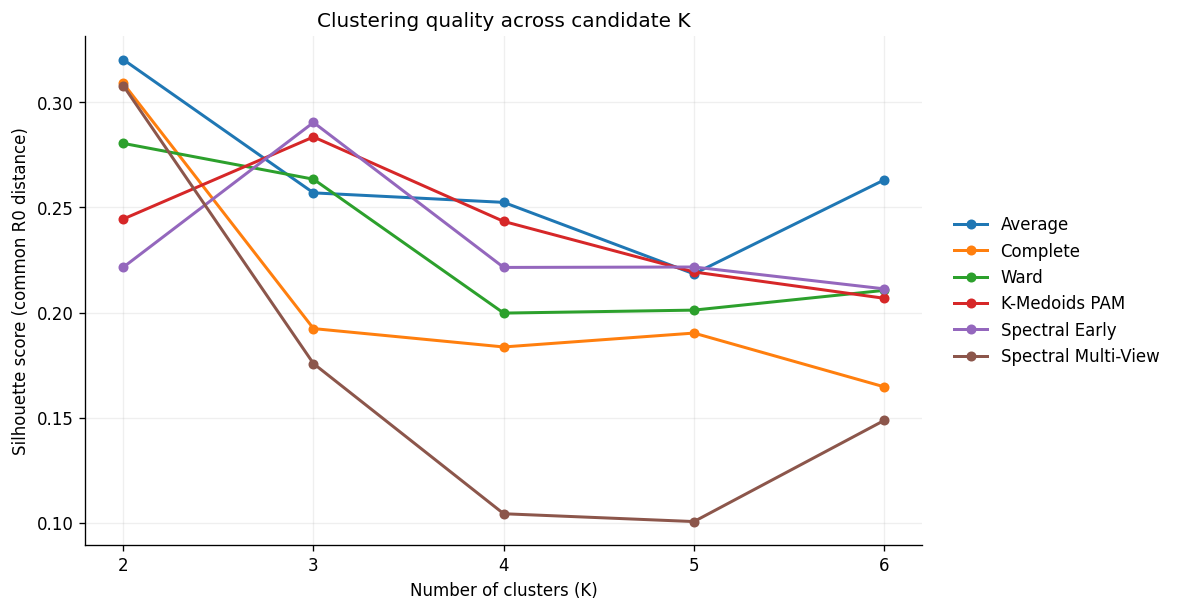

In [ ]:

# ============================================================
# CELL 10 — FIGURE 3: GRID SEARCH QUALITY
# ============================================================

best_by_k = (
    grid.groupby(["method", "K"], as_index=False)
    ["silhouette"]
    .max()
)

fig, ax = plt.subplots(figsize=(9, 5.5))

for method, sub in best_by_k.groupby("method"):
    sub = sub.sort_values("K")

    ax.plot(
        sub["K"],
        sub["silhouette"],
        marker="o",
        linewidth=1.8,
        markersize=5,
        label=METHOD_SHORT[method]
    )

ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette score (common R0 distance)")
ax.set_title("Clustering quality across candidate K")

ax.set_xticks([2, 3, 4, 5, 6])
ax.grid(alpha=0.2)

ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

save_figure(fig, "Fig03_GridSearch_Quality")


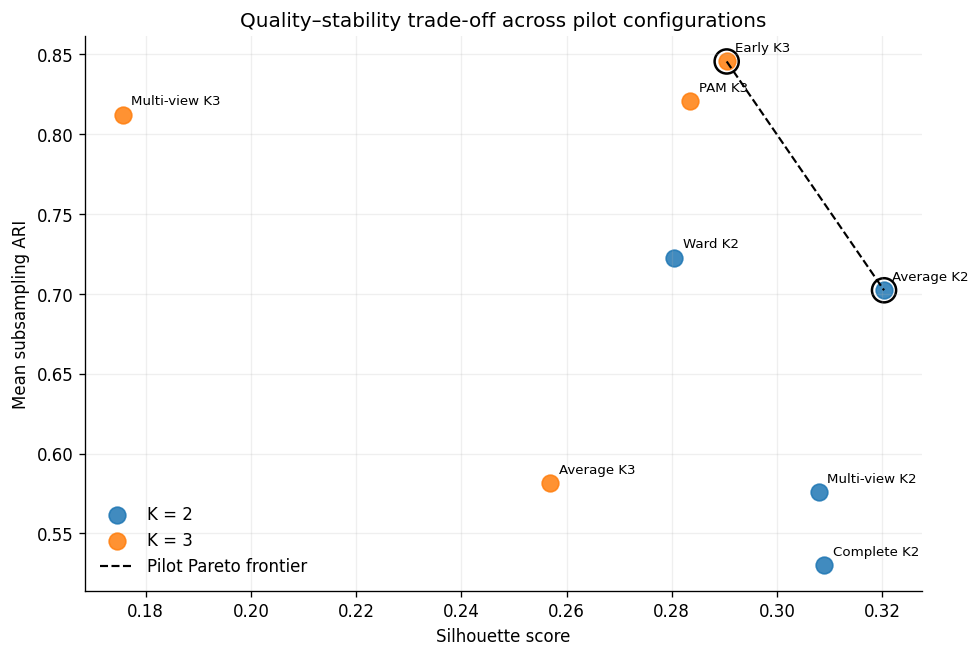

PILOT PARETO CONFIGURATIONS:


,model_id,K,silhouette_R0,mean_ARI,smallest_cluster
0,Hierarchical_Average_K2,2,0.3203,0.7023,4
3,Spectral_Early_K3_KG16,3,0.2904,0.8456,17


In [ ]:

# ============================================================
# CELL 11 — FIGURE 4: QUALITY-STABILITY TRADE-OFF
# Pilot only: not final model selection
# ============================================================

pilot = stab_summary.merge(
    grid[["model_id", "smallest_cluster"]],
    on="model_id",
    validate="one_to_one"
).copy()

Q = pilot["silhouette_R0"].to_numpy()
S = pilot["mean_ARI"].to_numpy()

# Non-dominated solutions: maximize both Q and S
pareto = np.ones(len(pilot), dtype=bool)

for i in range(len(pilot)):
    for j in range(len(pilot)):
        if i == j:
            continue

        if (
            Q[j] >= Q[i]
            and S[j] >= S[i]
            and (Q[j] > Q[i] or S[j] > S[i])
        ):
            pareto[i] = False
            break

pilot["pareto"] = pareto
pilot["short_name"] = pilot["model_id"].map(SHORT)

fig, ax = plt.subplots(figsize=(9, 6))

for K in sorted(pilot["K"].unique()):
    sub = pilot[pilot["K"] == K]

    ax.scatter(
        sub["silhouette_R0"],
        sub["mean_ARI"],
        s=100,
        alpha=0.85,
        label=f"K = {K}"
    )

for row in pilot.itertuples(index=False):
    ax.annotate(
        row.short_name,
        (row.silhouette_R0, row.mean_ARI),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=8
    )

front = pilot[pilot["pareto"]].sort_values(
    "silhouette_R0"
)

ax.plot(
    front["silhouette_R0"],
    front["mean_ARI"],
    linestyle="--",
    color="black",
    linewidth=1.3,
    label="Pilot Pareto frontier"
)

ax.scatter(
    front["silhouette_R0"],
    front["mean_ARI"],
    s=210,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5
)

ax.set_xlabel("Silhouette score")
ax.set_ylabel("Mean subsampling ARI")
ax.set_title(
    "Quality–stability trade-off across pilot configurations"
)

ax.grid(alpha=0.2)
ax.legend(frameon=False)

save_figure(fig, "Fig04_Quality_Stability_Tradeoff")

print("PILOT PARETO CONFIGURATIONS:")
display(
    pilot.loc[
        pilot["pareto"],
        [
            "model_id", "K",
            "silhouette_R0", "mean_ARI",
            "smallest_cluster"
        ]
    ].sort_values(
        "silhouette_R0",
        ascending=False
    ).round(4)
)


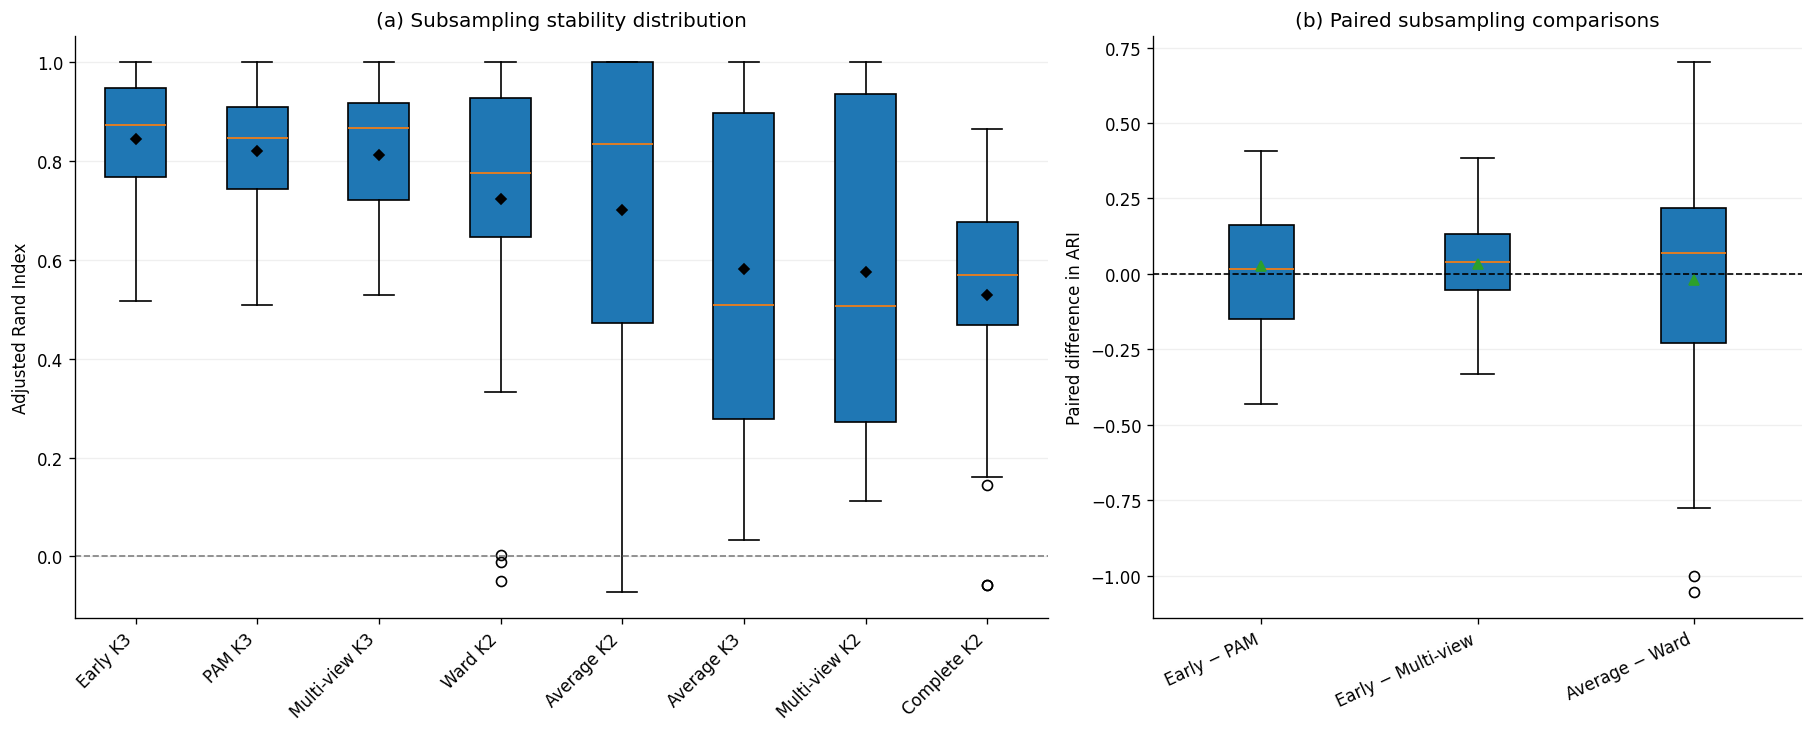

In [ ]:

# ============================================================
# CELL 12 — FIGURE 5: STABILITY DISTRIBUTIONS
# ============================================================

order = (
    stab_summary.sort_values(
        "mean_ARI", ascending=False
    )["model_id"]
    .tolist()
)

ari_data = [
    stab.loc[
        stab["model_id"] == model_id,
        "ARI"
    ].to_numpy()
    for model_id in order
]

wide = stab.pivot(
    index="repeat",
    columns="model_id",
    values="ARI"
)

comparisons = [
    (
        "Spectral_Early_K3_KG16",
        "KMedoids_PAM_K3",
        "Early − PAM"
    ),
    (
        "Spectral_Early_K3_KG16",
        "Spectral_MultiView_K3_KG24",
        "Early − Multi-view"
    ),
    (
        "Hierarchical_Average_K2",
        "Hierarchical_Ward_K2",
        "Average − Ward"
    )
]

diff_data = []
diff_labels = []

for a, b, label in comparisons:
    diff_data.append(
        (wide[a] - wide[b]).dropna().to_numpy()
    )
    diff_labels.append(label)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    gridspec_kw={"width_ratios": [1.5, 1]},
    constrained_layout=True
)

# Panel A: ARI by model
axes[0].boxplot(
    ari_data,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 4
    }
)

axes[0].set_xticks(
    range(1, len(order) + 1),
    [SHORT[m] for m in order],
    rotation=45,
    ha="right"
)

axes[0].axhline(
    0,
    linestyle="--",
    color="gray",
    linewidth=1
)

axes[0].set_ylabel("Adjusted Rand Index")
axes[0].set_title("(a) Subsampling stability distribution")
axes[0].grid(axis="y", alpha=0.2)

# Panel B: paired ARI differences
axes[1].boxplot(
    diff_data,
    patch_artist=True,
    showmeans=True
)

axes[1].set_xticks(
    range(1, len(diff_labels) + 1),
    diff_labels,
    rotation=25,
    ha="right"
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_ylabel("Paired difference in ARI")
axes[1].set_title("(b) Paired subsampling comparisons")
axes[1].grid(axis="y", alpha=0.2)

save_figure(fig, "Fig05_Stability_Distribution")


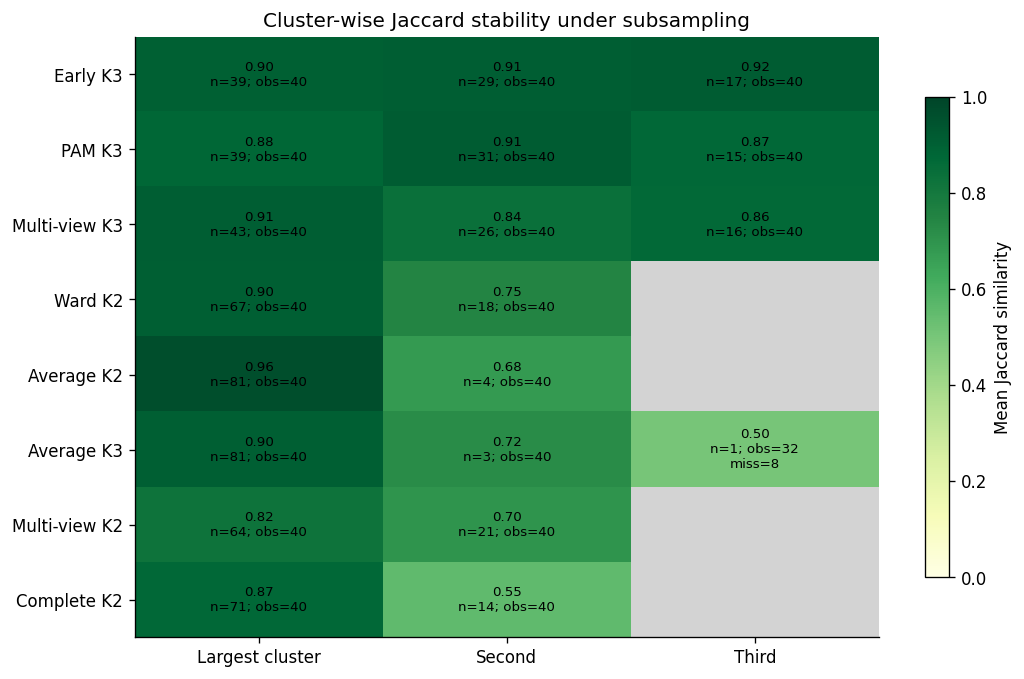

In [ ]:

# ============================================================
# CELL 13 — FIGURE 6: CLUSTER-WISE STABILITY
# ============================================================

order = (
    stab_summary.sort_values(
        "mean_ARI", ascending=False
    )["model_id"]
    .tolist()
)

heat = np.full(
    (len(order), 3),
    np.nan
)

annotations = [
    ["", "", ""]
    for _ in order
]

for i, model_id in enumerate(order):

    labels = labels_df[model_id].to_numpy(
        dtype=int
    )

    cluster_ids, counts = np.unique(
        labels,
        return_counts=True
    )

    # Descending cluster size, deterministic tie handling
    ranked = sorted(
        zip(cluster_ids, counts),
        key=lambda x: (-x[1], x[0])
    )

    for rank, (cluster_id, size) in enumerate(ranked):

        record = cluster_stab.loc[
            (cluster_stab["model_id"] == model_id)
            & (
                cluster_stab["reference_cluster"]
                == cluster_id
            )
        ]

        assert len(record) == 1

        record = record.iloc[0]

        value = float(record["mean_jaccard"])
        n_observed = int(record["n_observed"])
        n_missing = int(record["n_missing"])

        heat[i, rank] = value

        annotations[i][rank] = (
            f"{value:.2f}\n"
            f"n={size}; obs={n_observed}"
        )

        if n_missing:
            annotations[i][rank] += (
                f"\nmiss={n_missing}"
            )

masked = np.ma.masked_invalid(heat)

cmap = plt.colormaps["YlGn"].copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(10, 6.5))

im = ax.imshow(
    masked,
    cmap=cmap,
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(
    [0, 1, 2],
    ["Largest cluster", "Second", "Third"]
)

ax.set_yticks(
    range(len(order)),
    [SHORT[m] for m in order]
)

for i in range(len(order)):
    for j in range(3):

        if np.isfinite(heat[i, j]):
            ax.text(
                j, i,
                annotations[i][j],
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if heat[i, j] < 0.45
                    else "black"
                )
            )

ax.set_title(
    "Cluster-wise Jaccard stability under subsampling"
)

fig.colorbar(
    im,
    ax=ax,
    label="Mean Jaccard similarity",
    shrink=0.8
)

save_figure(fig, "Fig06_Clusterwise_Jaccard")


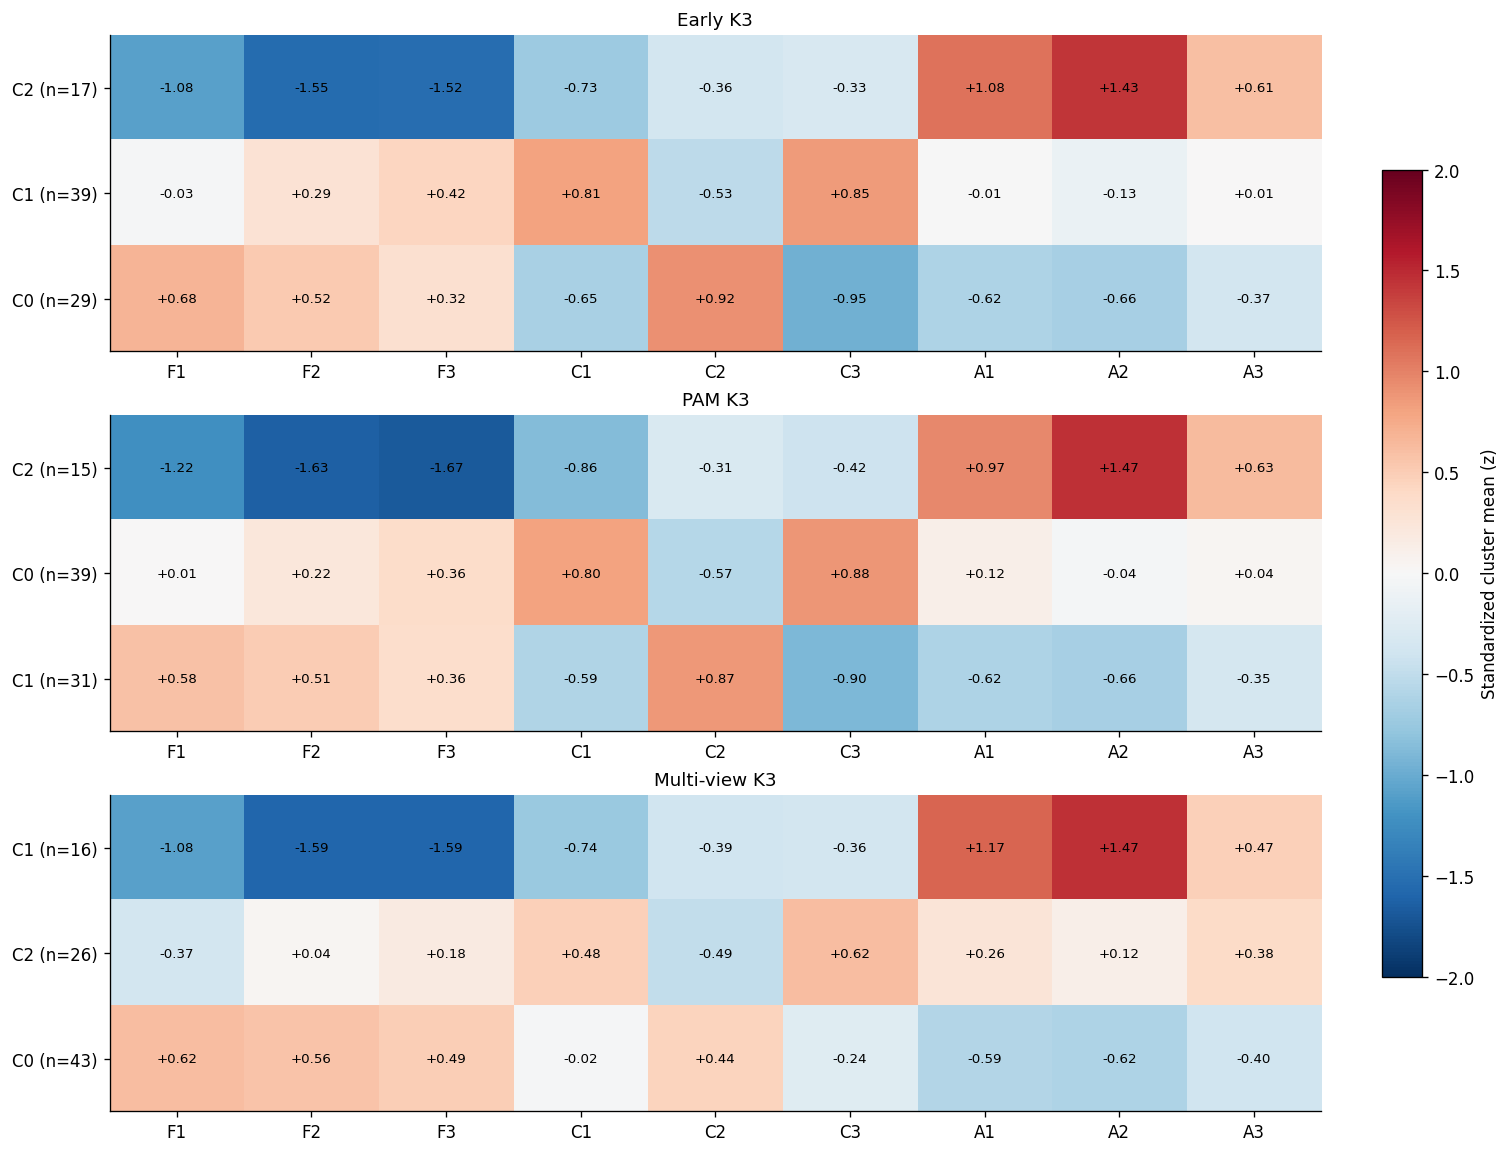

In [ ]:

# ============================================================
# CELL 14 — FIGURE 7: CLUSTER PROFILE HEATMAP
# ============================================================

MODELS = [
    "Spectral_Early_K3_KG16",
    "KMedoids_PAM_K3",
    "Spectral_MultiView_K3_KG24"
]

FEATURE_CODES = [
    "F1", "F2", "F3",
    "C1", "C2", "C3",
    "A1", "A2", "A3"
]

FEATURE_COLUMNS = [
    c for c in profiles.columns
    if c.startswith("zmean_")
]

assert len(FEATURE_COLUMNS) == 9

plot_matrices = []
row_labels = []

for model_id in MODELS:

    sub = profiles.loc[
        profiles["model_id"] == model_id
    ].copy()

    assert len(sub) == 3

    # Order by food affordability score for readability.
    # This does NOT formally align partitions.
    sub = sub.sort_values(
        "zmean_F2_ikp_keterjangkauan"
    )

    plot_matrices.append(
        sub[FEATURE_COLUMNS].to_numpy(
            dtype=float
        )
    )

    row_labels.append([
        f"C{int(r.cluster)} (n={int(r.n)})"
        for r in sub.itertuples(index=False)
    ])

max_abs = max(
    2.0,
    max(np.abs(M).max() for M in plot_matrices)
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(12.5, 9.5),
    constrained_layout=True
)

for ax, model_id, matrix, labels in zip(
    axes,
    MODELS,
    plot_matrices,
    row_labels
):

    im = ax.imshow(
        matrix,
        cmap="RdBu_r",
        vmin=-max_abs,
        vmax=max_abs,
        aspect="auto"
    )

    ax.set_xticks(
        range(9),
        FEATURE_CODES
    )

    ax.set_yticks(
        range(3),
        labels
    )

    ax.set_title(
        SHORT[model_id],
        fontsize=11
    )

    for i in range(3):
        for j in range(9):
            ax.text(
                j, i,
                f"{matrix[i, j]:+.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

fig.colorbar(
    im,
    ax=axes,
    label="Standardized cluster mean (z)",
    shrink=0.75
)

save_figure(fig, "Fig07_Cluster_Profiles")
